In [10]:
import tabpfn_client
from tabpfn_client import TabPFNClassifier, TabPFNRegressor, set_access_token
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer
from tabpfn_extensions.interpretability.pdp import partial_dependence_plots
import matplotlib
import matplotlib.pyplot as plt
import warnings
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
from scipy.stats import pearsonr, spearmanr
warnings.filterwarnings('ignore')




# Authenticate
API_TOKEN = "tabpfn_sk_-8MQiln6CgpNd73pkj_AnXet7LDIZWiwVpQWS26aEnw"
tabpfn_client.set_access_token(API_TOKEN)

In [2]:
df = pd.read_csv(r"C:\Users\Pratham Shah\Downloads\Tubingen\Codes\MiCRM_Final_Dataset\community_index_v10.csv")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nTarget (community_suppression) statistics:")
print(df['community_suppression'].describe().round(4))

print("\nRows per diversity level:")
print(df['diversity_level'].value_counts().sort_index())

print("\nRows per community size:")
print(df['community_size'].value_counts().sort_index())

Dataset shape: 75,000 rows × 168 columns

Target (community_suppression) statistics:
count    75000.0000
mean         0.5166
std          0.3328
min          0.0000
25%          0.2331
50%          0.4961
75%          0.8426
max          0.9995
Name: community_suppression, dtype: float64

Rows per diversity level:
diversity_level
1     15000
2     15000
4     15000
8     15000
16    15000
Name: count, dtype: int64

Rows per community size:
community_size
12    15000
16    15000
24    15000
32    15000
48    15000
Name: count, dtype: int64


In [7]:
r0_cols = [f"R0_c{k}" for k in range(1, 21)]

active_cols = [f"active_c{k}" for k in range(1, 21)]

structural_cols = ['community_size', 'diversity_level']

feature_cols = r0_cols + active_cols + structural_cols

print(f"Feature count:          {len(feature_cols)}  (vs 142 in the composition model)")
print(f"  R0 concentrations:    {len(r0_cols)}")
print(f"  Active flags:         {len(active_cols)}")
print(f"  Structural:           {len(structural_cols)}")
print(f"  Species membership:   0  ← intentionally excluded")


X = df[feature_cols]
y = df['community_suppression']
groups = df["broth_id"].copy()

print(f"\nX shape: {X.shape}    y shape: {y.shape}")

Feature count:          42  (vs 142 in the composition model)
  R0 concentrations:    20
  Active flags:         20
  Structural:           2
  Species membership:   0  ← intentionally excluded

X shape: (75000, 42)    y shape: (75000,)


In [8]:
strat_key = df["community_size"].astype(str) + "_" + df["diversity_level"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=strat_key
)

diversity_test = df.loc[X_test.index, "diversity_level"].values
community_size_test = df.loc[X_test.index, "community_size"].values

print(f"Train set: {X_train.shape[0]:,} rows")
print(f"Test set:  {X_test.shape[0]:,} rows")
print(f"Unique broths: {len(np.unique(groups))}")

Train set: 60,000 rows
Test set:  15,000 rows
Unique broths: 150


In [11]:
model = TabPFNRegressor(
    n_estimators=8,
    random_state=42,
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
pearson = pearsonr(y_test, predictions).statistic
spearman = spearmanr(y_test, predictions).statistic

print("TabPFN-3: Stratified Row-wise Test Set Performance")
print(f"  R2       : {r2:.4f}")
print(f"  MAE      : {mae:.4f}")
print(f"  RMSE     : {rmse:.4f}")
print(f"  Pearson  : {pearson:.4f}")
print(f"  Spearman : {spearman:.4f}")

00:01 Fitting... |

00:06 Fitting... Done!
00:00 Predicting... \

00:15 Predicting... Done!
TabPFN-3: Stratified Row-wise Test Set Performance
  R2       : 0.7957
  MAE      : 0.0987
  RMSE     : 0.1502
  Pearson  : 0.8924
  Spearman : 0.8924


In [12]:
results_df = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred": predictions,
    "diversity_level": diversity_test,
    "community_size": community_size_test,
})


def safe_pearson(y_true_arr, y_pred_arr):
    y_t = np.asarray(y_true_arr)
    y_p = np.asarray(y_pred_arr)

    if len(y_t) < 2:
        return np.nan
    if np.std(y_t) < 1e-12 or np.std(y_p) < 1e-12:
        return np.nan

    return pearsonr(y_t, y_p).statistic


def safe_spearman(y_true_arr, y_pred_arr):
    y_t = np.asarray(y_true_arr)
    y_p = np.asarray(y_pred_arr)

    if len(y_t) < 2:
        return np.nan
    if np.std(y_t) < 1e-12 or np.std(y_p) < 1e-12:
        return np.nan

    return spearmanr(y_t, y_p).statistic


def condition_metrics(y_true_arr, y_pred_arr):
    y_t = np.asarray(y_true_arr)
    y_p = np.asarray(y_pred_arr)

    r2_ = r2_score(y_t, y_p)
    mae_ = mean_absolute_error(y_t, y_p)
    rmse_ = np.sqrt(mean_squared_error(y_t, y_p))
    pr = safe_pearson(y_t, y_p)
    sr = safe_spearman(y_t, y_p)

    bias = float(np.mean(y_p - y_t))
    std_true = float(np.std(y_t))
    nrmse = rmse_ / std_true if std_true > 1e-8 else np.nan

    return {
        "n": len(y_t),
        "r2": r2_,
        "mae": mae_,
        "rmse": rmse_,
        "pearson_r": pr,
        "spearman_r": sr,
        "bias": bias,
        "std_true": std_true,
        "nrmse": nrmse,
    }


def reliability_flag(std_true):
    if std_true < 0.05:
        return "LOW"
    elif std_true < 0.10:
        return "MED"
    return "OK"


hdr = (
    f"{'':6} {'R2':>7} {'MAE':>7} {'RMSE':>7} {'nRMSE':>7} "
    f"{'Pearson':>8} {'Spearman':>9} {'Bias':>8} {'std(y)':>7} "
    f"{'N':>6} {'Flag':>5}"
)

print("\nBy diversity level:")
print(hdr)
print("-" * len(hdr))

for d, grp in results_df.groupby("diversity_level"):
    m = condition_metrics(grp["y_true"], grp["y_pred"])
    flag = reliability_flag(m["std_true"])

    print(
        f"D={d:<3}  "
        f"{m['r2']:>7.4f} "
        f"{m['mae']:>7.4f} "
        f"{m['rmse']:>7.4f} "
        f"{m['nrmse']:>7.4f} "
        f"{m['pearson_r']:>8.4f} "
        f"{m['spearman_r']:>9.4f} "
        f"{m['bias']:>8.4f} "
        f"{m['std_true']:>7.4f} "
        f"{m['n']:>6,} "
        f"{flag:>5}"
    )

print("\nBy community size:")
print(hdr)
print("-" * len(hdr))

for n, grp in results_df.groupby("community_size"):
    m = condition_metrics(grp["y_true"], grp["y_pred"])
    flag = reliability_flag(m["std_true"])

    print(
        f"N={n:<3}  "
        f"{m['r2']:>7.4f} "
        f"{m['mae']:>7.4f} "
        f"{m['rmse']:>7.4f} "
        f"{m['nrmse']:>7.4f} "
        f"{m['pearson_r']:>8.4f} "
        f"{m['spearman_r']:>9.4f} "
        f"{m['bias']:>8.4f} "
        f"{m['std_true']:>7.4f} "
        f"{m['n']:>6,} "
        f"{flag:>5}"
    )


By diversity level:
            R2     MAE    RMSE   nRMSE  Pearson  Spearman     Bias  std(y)      N  Flag
---------------------------------------------------------------------------------------
D=1     0.8614  0.0796  0.1612  0.3723   0.9302    0.9456  -0.0203  0.4330  3,000    OK
D=2     0.7655  0.1125  0.1726  0.4843   0.8753    0.8753   0.0091  0.3564  3,000    OK
D=4     0.6488  0.1271  0.1744  0.5926   0.8060    0.8174  -0.0015  0.2944  3,000    OK
D=8     0.7377  0.1017  0.1331  0.5121   0.8592    0.8446  -0.0016  0.2600  3,000    OK
D=16    0.6989  0.0725  0.0945  0.5488   0.8366    0.8202   0.0006  0.1722  3,000    OK

By community size:
            R2     MAE    RMSE   nRMSE  Pearson  Spearman     Bias  std(y)      N  Flag
---------------------------------------------------------------------------------------
N=12    0.6693  0.1307  0.1883  0.5751   0.8190    0.7874  -0.0085  0.3274  3,000    OK
N=16    0.7196  0.1191  0.1752  0.5295   0.8491    0.8341   0.0009  0.3309  3,0

In [14]:
from sklearn.model_selection import train_test_split, GroupKFold

gkf = GroupKFold(n_splits=5)

oof_pred = np.full(len(X), np.nan)
fold_membership = np.full(len(X), -1)

fold_r2 = []
fold_mae = []
fold_rmse = []
fold_pearson = []
fold_spearman = []

print("\nGroupKFold evaluation: held-out broths")

for fold_num, (tr_idx, te_idx) in enumerate(
        gkf.split(X, y, groups=groups), start=1):

    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_te, y_te = X.iloc[te_idx], y.iloc[te_idx]

    groups_tr = groups.iloc[tr_idx]
    groups_te = groups.iloc[te_idx]

    assert len(set(groups_tr).intersection(set(groups_te))) == 0

    held_broths = sorted(set(groups_te))
    held_divs = sorted(df.iloc[te_idx]["diversity_level"].unique())

    print(
        f"\nFold {fold_num}: broths={held_broths}  "
        f"diversity levels={held_divs}  n_test={len(X_te):,}"
    )

    m_fold = TabPFNRegressor(
        n_estimators=8,
        random_state=42 + fold_num,
    )

    m_fold.fit(X_tr, y_tr)
    yp_fold = m_fold.predict(X_te)

    oof_pred[te_idx] = yp_fold
    fold_membership[te_idx] = fold_num

    r2_f = r2_score(y_te, yp_fold)
    mae_f = mean_absolute_error(y_te, yp_fold)
    rmse_f = np.sqrt(mean_squared_error(y_te, yp_fold))
    pearson_f = safe_pearson(y_te, yp_fold)
    spearman_f = safe_spearman(y_te, yp_fold)

    fold_r2.append(r2_f)
    fold_mae.append(mae_f)
    fold_rmse.append(rmse_f)
    fold_pearson.append(pearson_f)
    fold_spearman.append(spearman_f)

    print(
        f"  R2={r2_f:.4f}  "
        f"MAE={mae_f:.4f}  "
        f"RMSE={rmse_f:.4f}  "
        f"Pearson={pearson_f:.4f}  "
        f"Spearman={spearman_f:.4f}"
    )

valid_mask = ~np.isnan(oof_pred)

y_oof_true = y.values[valid_mask]
y_oof_pred = oof_pred[valid_mask]

r2_oof_pooled = r2_score(y_oof_true, y_oof_pred)
mae_oof_pooled = mean_absolute_error(y_oof_true, y_oof_pred)
rmse_oof_pooled = np.sqrt(mean_squared_error(y_oof_true, y_oof_pred))
pearson_oof_pooled = safe_pearson(y_oof_true, y_oof_pred)
spearman_oof_pooled = safe_spearman(y_oof_true, y_oof_pred)

print(f"\nPooled out-of-fold metrics across all {gkf.n_splits} folds:")
print(f"  R2       = {r2_oof_pooled:.4f}")
print(f"  MAE      = {mae_oof_pooled:.4f}")
print(f"  RMSE     = {rmse_oof_pooled:.4f}")
print(f"  Pearson  = {pearson_oof_pooled:.4f}")
print(f"  Spearman = {spearman_oof_pooled:.4f}")

print("\nFold-wise summary:")
print(f"  R2:       mean={np.mean(fold_r2):.4f}  std={np.std(fold_r2):.4f}")
print(f"  MAE:      mean={np.mean(fold_mae):.4f}  std={np.std(fold_mae):.4f}")
print(f"  RMSE:     mean={np.mean(fold_rmse):.4f}  std={np.std(fold_rmse):.4f}")
print(f"  Pearson:  mean={np.nanmean(fold_pearson):.4f}  std={np.nanstd(fold_pearson):.4f}")
print(f"  Spearman: mean={np.nanmean(fold_spearman):.4f}  std={np.nanstd(fold_spearman):.4f}")

print(f"\nCompare to stratified-split R2={r2:.4f}")
print(f"Drop: {r2 - r2_oof_pooled:.4f}")


GroupKFold evaluation: held-out broths

Fold 1: broths=['Broth_005', 'Broth_010', 'Broth_015', 'Broth_020', 'Broth_025', 'Broth_030', 'Broth_035', 'Broth_040', 'Broth_045', 'Broth_050', 'Broth_055', 'Broth_060', 'Broth_065', 'Broth_070', 'Broth_075', 'Broth_080', 'Broth_085', 'Broth_090', 'Broth_095', 'Broth_100', 'Broth_105', 'Broth_110', 'Broth_115', 'Broth_120', 'Broth_125', 'Broth_130', 'Broth_135', 'Broth_140', 'Broth_145', 'Broth_150']  diversity levels=[np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16)]  n_test=15,000
00:16 Fitting... Done!
00:19 Predicting... Done!
  R2=0.5770  MAE=0.1544  RMSE=0.2138  Pearson=0.7597  Spearman=0.7529

Fold 2: broths=['Broth_004', 'Broth_009', 'Broth_014', 'Broth_019', 'Broth_024', 'Broth_029', 'Broth_034', 'Broth_039', 'Broth_044', 'Broth_049', 'Broth_054', 'Broth_059', 'Broth_064', 'Broth_069', 'Broth_074', 'Broth_079', 'Broth_084', 'Broth_089', 'Broth_094', 'Broth_099', 'Broth_104', 'Broth_109', 'Broth_114', 'Broth_119', 'Brot

Saved: tabpfn_02_diagnostics.png


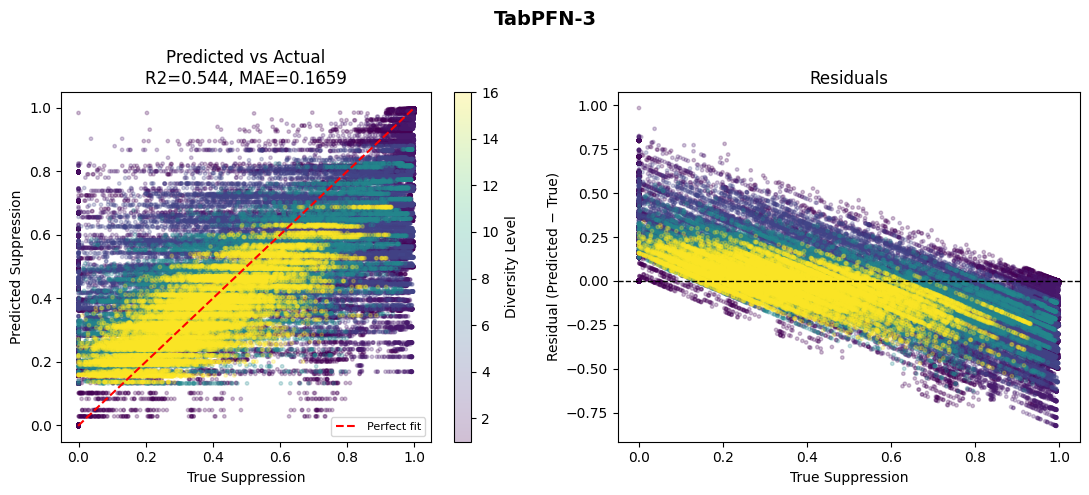

Saved: tabpfn_02_diversity.png


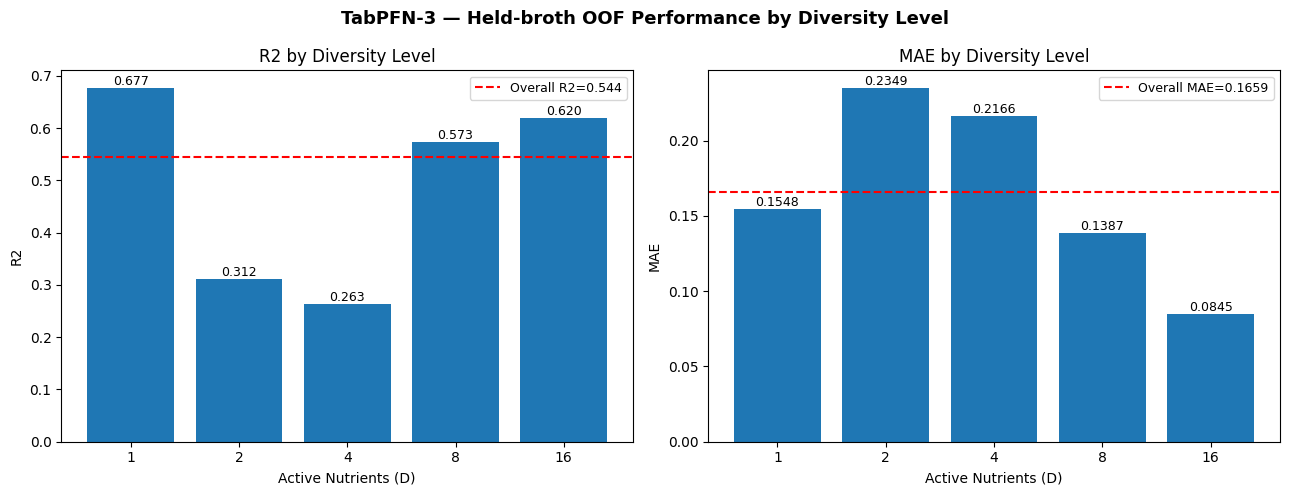

Saved: tabpfn_02_community_size.png


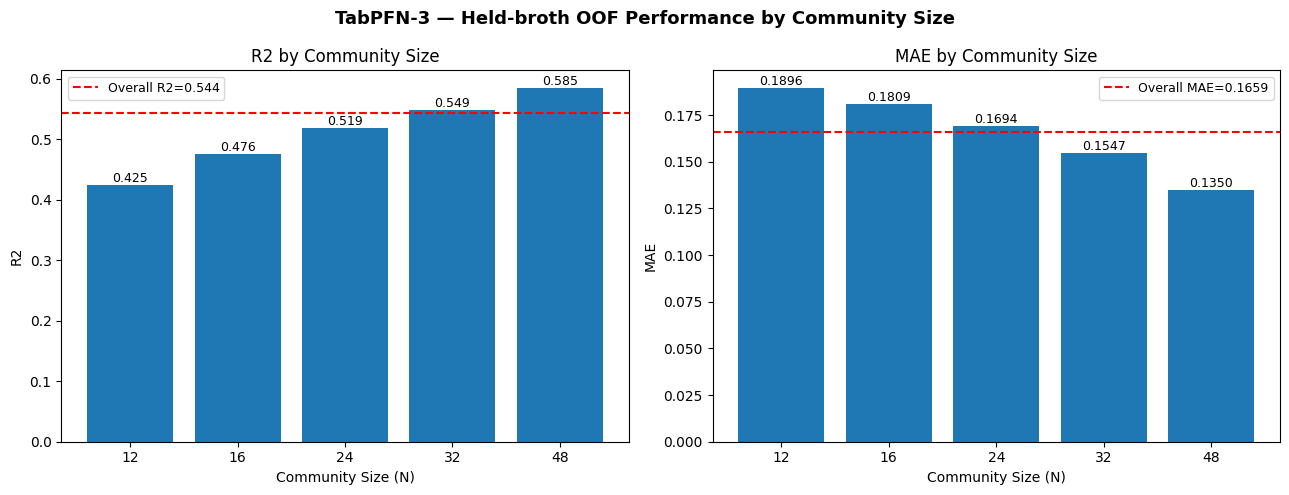

In [15]:
oof_results_df = pd.DataFrame({
    "y_true": y.values,
    "y_pred": oof_pred,
    "fold": fold_membership,
    "broth_id": groups.values,
    "diversity_level": df["diversity_level"].values,
    "community_size": df["community_size"].values,
})

oof_results_df = oof_results_df.dropna(subset=["y_pred"]).copy()

y_plot = oof_results_df["y_true"].values
pred_plot = oof_results_df["y_pred"].values
div_plot = oof_results_df["diversity_level"].values
size_plot = oof_results_df["community_size"].values

r2_plot = r2_score(y_plot, pred_plot)
mae_plot = mean_absolute_error(y_plot, pred_plot)
rmse_plot = np.sqrt(mean_squared_error(y_plot, pred_plot))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("TabPFN-3", fontsize=14, fontweight="bold")

ax = axes[0]
sc = ax.scatter(
    y_plot,
    pred_plot,
    alpha=0.25,
    s=6,
    c=div_plot,
    cmap="viridis"
)

plt.colorbar(sc, ax=ax, label="Diversity Level")

lims = [
    min(y_plot.min(), pred_plot.min()),
    max(y_plot.max(), pred_plot.max())
]

ax.plot(lims, lims, "r--", lw=1.5, label="Perfect fit")
ax.set_xlabel("True Suppression")
ax.set_ylabel("Predicted Suppression")
ax.set_title(f"Predicted vs Actual\nR2={r2_plot:.3f}, MAE={mae_plot:.4f}")
ax.legend(fontsize=8)

ax2 = axes[1]
residuals = pred_plot - y_plot

ax2.scatter(
    y_plot,
    residuals,
    alpha=0.25,
    s=6,
    c=div_plot,
    cmap="viridis"
)

ax2.axhline(0, color="black", lw=1, ls="--")
ax2.set_xlabel("True Suppression")
ax2.set_ylabel("Residual (Predicted − True)")
ax2.set_title("Residuals")

plt.tight_layout()
plt.savefig("tabpfn_02_diagnostics.png", dpi=150, bbox_inches="tight")
print("Saved: tabpfn_02_diagnostics.png")
plt.show()


diversity_levels = sorted(oof_results_df["diversity_level"].unique())

per_d_r2 = []
per_d_mae = []

for d in diversity_levels:
    grp = oof_results_df[oof_results_df["diversity_level"] == d]
    per_d_r2.append(r2_score(grp["y_true"], grp["y_pred"]))
    per_d_mae.append(mean_absolute_error(grp["y_true"], grp["y_pred"]))

fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5))
fig2.suptitle("TabPFN-3 — Held-broth OOF Performance by Diversity Level", fontsize=13, fontweight="bold")

d_labels = [str(int(d)) for d in diversity_levels]

ax_d_r2 = axes2[0]
bars_d_r2 = ax_d_r2.bar(d_labels, per_d_r2)
ax_d_r2.axhline(r2_plot, color="red", ls="--", lw=1.5, label=f"Overall R2={r2_plot:.3f}")
ax_d_r2.set_xlabel("Active Nutrients (D)")
ax_d_r2.set_ylabel("R2")
ax_d_r2.set_title("R2 by Diversity Level")
ax_d_r2.legend(fontsize=9)

for bar, val in zip(bars_d_r2, per_d_r2):
    ax_d_r2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_d_mae = axes2[1]
bars_d_mae = ax_d_mae.bar(d_labels, per_d_mae)
ax_d_mae.axhline(mae_plot, color="red", ls="--", lw=1.5, label=f"Overall MAE={mae_plot:.4f}")
ax_d_mae.set_xlabel("Active Nutrients (D)")
ax_d_mae.set_ylabel("MAE")
ax_d_mae.set_title("MAE by Diversity Level")
ax_d_mae.legend(fontsize=9)

for bar, val in zip(bars_d_mae, per_d_mae):
    ax_d_mae.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("tabpfn_02_diversity.png", dpi=150, bbox_inches="tight")
print("Saved: tabpfn_02_diversity.png")
plt.show()


size_levels = sorted(oof_results_df["community_size"].unique())

per_size_r2 = []
per_size_mae = []

for n in size_levels:
    grp = oof_results_df[oof_results_df["community_size"] == n]
    per_size_r2.append(r2_score(grp["y_true"], grp["y_pred"]))
    per_size_mae.append(mean_absolute_error(grp["y_true"], grp["y_pred"]))

fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5))
fig3.suptitle("TabPFN-3 — Held-broth OOF Performance by Community Size", fontsize=13, fontweight="bold")

size_labels = [str(int(n)) for n in size_levels]

ax_s_r2 = axes3[0]
bars_s_r2 = ax_s_r2.bar(size_labels, per_size_r2)
ax_s_r2.axhline(r2_plot, color="red", ls="--", lw=1.5, label=f"Overall R2={r2_plot:.3f}")
ax_s_r2.set_xlabel("Community Size (N)")
ax_s_r2.set_ylabel("R2")
ax_s_r2.set_title("R2 by Community Size")
ax_s_r2.legend(fontsize=9)

for bar, val in zip(bars_s_r2, per_size_r2):
    ax_s_r2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_s_mae = axes3[1]
bars_s_mae = ax_s_mae.bar(size_labels, per_size_mae)
ax_s_mae.axhline(mae_plot, color="red", ls="--", lw=1.5, label=f"Overall MAE={mae_plot:.4f}")
ax_s_mae.set_xlabel("Community Size (N)")
ax_s_mae.set_ylabel("MAE")
ax_s_mae.set_title("MAE by Community Size")
ax_s_mae.legend(fontsize=9)

for bar, val in zip(bars_s_mae, per_size_mae):
    ax_s_mae.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("tabpfn_02_community_size.png", dpi=150, bbox_inches="tight")
print("Saved: tabpfn_02_community_size.png")
plt.show()


Computing SHAP values...
00:01 Fitting... |

00:06 Fitting... Done!
00:00 Predicting... |

00:17 Predicting... Done!


  0%|          | 0/30 [00:00<?, ?it/s]

00:00 Predicting... |

...

00:14 Predicting... Done!
00:24 Predicting... Done!
00:00 Predicting... |

00:15 Predicting... Done!
00:26 Predicting... Done!
00:00 Predicting... \

00:14 Predicting... Done!
00:22 Predicting... Done!
00:00 Predicting... \

00:14 Predicting... Done!
00:24 Predicting... Done!
00:00 Predicting... \

00:14 Predicting... Done!
00:23 Predicting... Done!
SHAP computation complete.
Saved: tabpfn_shap_bar_02.png


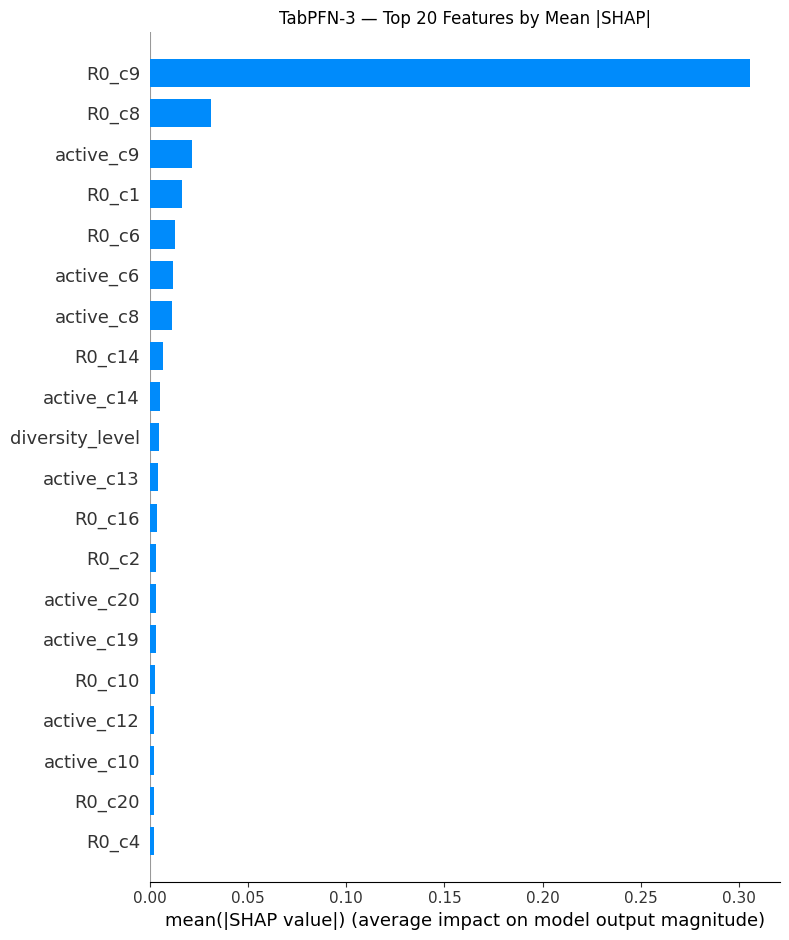

Saved: tabpfn_shap_beeswarm_02.png


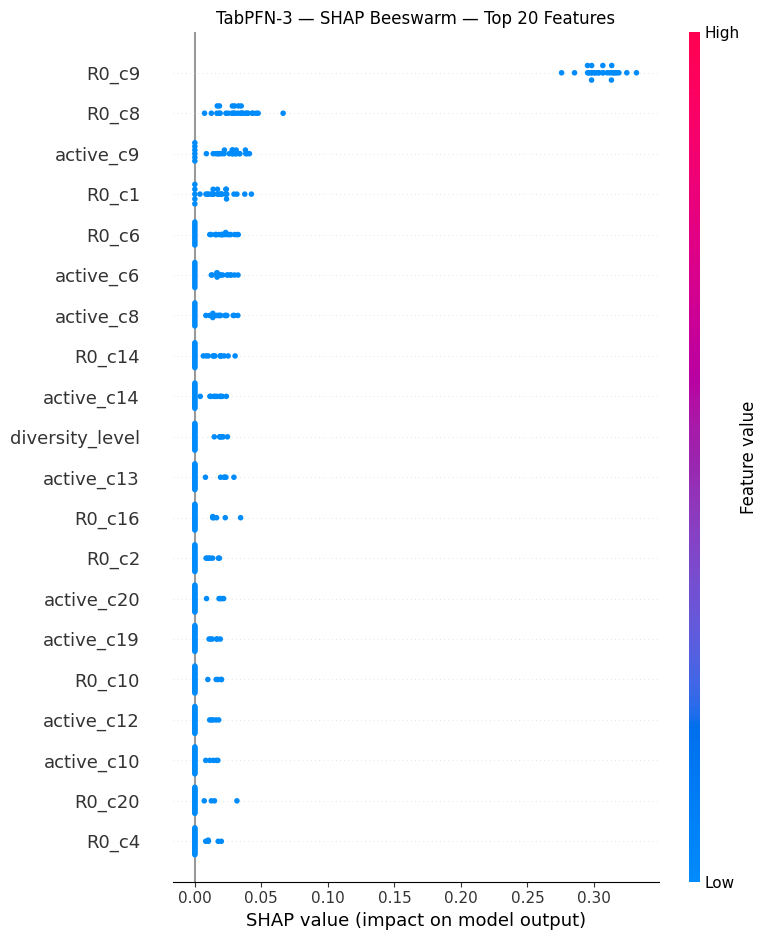

In [17]:
import shap

print("\nComputing SHAP values...")

final_model = TabPFNRegressor(
    n_estimators=8,
    random_state=42,
)

final_model.fit(X, y)

N_EXPLAIN = 30

feature_names = list(X.columns)

X_np = X.values
X_explain_np = X.iloc[:N_EXPLAIN].values

background = shap.sample(X_np, 100, random_state=42)


def predict_fn(X_input):
    return final_model.predict(pd.DataFrame(X_input, columns=feature_names))


explainer = shap.KernelExplainer(
    model=predict_fn,
    data=background,
)

shap_values = explainer.shap_values(
    X_explain_np,
    nsamples=256,
)

print("SHAP computation complete.")

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    show=False,
    plot_type="bar",
)

plt.title("TabPFN-3 — Top 20 Features by Mean |SHAP|")
plt.tight_layout()
plt.savefig("tabpfn_shap_bar_02.png", dpi=150, bbox_inches="tight")
print("Saved: tabpfn_shap_bar_02.png")
plt.show()

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    show=False,
)

plt.title("TabPFN-3 — SHAP Beeswarm — Top 20 Features")
plt.tight_layout()
plt.savefig("tabpfn_shap_beeswarm_02.png", dpi=150, bbox_inches="tight")
print("Saved: tabpfn_shap_beeswarm_02.png")
plt.show()